<div style='background:#000000;border-radius:10px;padding:26px 30px;border-top:6px solid #3777FF;border-bottom:3px solid #0EE071;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif'>
<p style='color:#0EE071;margin:0;letter-spacing:2px;font-size:12px'>NOVA IMS · ENTERPRISE DATA SCIENCE BOOTCAMP 2026 · PROJETO D</p>
<h1 style='color:#FFFFFF;margin:6px 0 4px 0'>Telco Customer Churn · <span style='color:#3777FF'>Retention Management</span></h1>
<p style='color:#FFFFFF;margin:0;font-size:15px'>Notebook 02 — Modelação ensemble, avaliação contra o benchmark IBM e priorização por valor</p>
</div>

<div style='background:#000000;border-left:6px solid #3777FF;border-radius:8px;padding:14px 20px;margin:4px 0;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif'><h2 style='color:#3777FF;margin:0 0 8px 0'>Índice — Estrutura do notebook</h2><div style='color:#FFFFFF;font-size:14px;line-height:1.6'>
<p>Implementa os <b style='color:#3777FF'>próximos passos</b> definidos na secção 14 do notebook 01.
Pré-requisito: correr primeiro <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>01_preprocessing_eda.ipynb</code> (gera <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>data/processed/</code> e <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>preprocessing_config.joblib</code>).</p>
<ol style='margin:4px 0'>
<li>Setup do ambiente</li><li>Carregamento dos artefactos</li><li>Tuning dos modelos base</li>
<li>Ensembles e seleção do modelo</li><li>Satisfaction Score — com e sem</li><li>City com TargetEncoder</li>
<li>Avaliação final no holdout</li><li>Interpretação</li><li>Priorização P(churn) × CLTV</li>
<li>Exportação</li><li>Conclusões para o relatório</li></ol></div></div>

<div style='background:#000000;border-left:6px solid #3777FF;border-radius:8px;padding:14px 20px;margin:4px 0;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif'><h2 style='color:#3777FF;margin:0 0 8px 0'>1 · Setup do ambiente</h2><div style='color:#FFFFFF;font-size:14px;line-height:1.6'>
<p>Mesmo setup do notebook 01. O módulo novo <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>modelling</code> contém o tuning, os ensembles, a avaliação e a priorização.</p>
<p><code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>N_ITER</code> controla o nº de combinações testadas por modelo no <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>RandomizedSearchCV</code> — reduzir para correr mais depressa.</p></div></div>

In [4]:
# --- Bibliotecas ---
import sys
import warnings
from pathlib import Path

import joblib
import pandas as pd
from IPython.display import display
from sklearn.inspection import permutation_importance

# --- Encontrar a pasta do projeto (a que tem a pasta "src") ---
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

# --- Módulos do próprio projeto (pasta src/telco_churn) ---
from telco_churn import modelling, plots
from telco_churn.config import ARTIFACTS_DIR, DATA_PROCESSED, TAB_DIR, ensure_dirs
from telco_churn.style import apply_theme, style_table

# --- Opções ---
warnings.filterwarnings("ignore")         # esconder avisos
pd.set_option("display.max_columns", 60)  # mostrar mais colunas nas tabelas

SHOW = True    # True = mostrar os gráficos (são sempre guardados em ficheiro)
N_ITER = 20    # nº de combinações testadas por modelo (menos = mais rápido)

ensure_dirs()
apply_theme()
print("Pasta do projeto:", ROOT)

Pasta do projeto: c:\Users\j3gra\Documents\class2\Bootcamp\telco-churn-retention


<div style='background:#000000;border-left:6px solid #3777FF;border-radius:8px;padding:14px 20px;margin:4px 0;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif'><h2 style='color:#3777FF;margin:0 0 8px 0'>2 · Carregamento dos artefactos</h2><div style='color:#FFFFFF;font-size:14px;line-height:1.6'>
<p>Carrega <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>preprocessing_config.joblib</code> (listas de features e target) e os CSV de treino, teste e Joined.
Os CSV são lidos com <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>keep_default_na=False</code> para preservar o literal <i>None</i> em <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>Offer</code> e <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>Internet Type</code>.</p>
<p><code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>City</code> não foi exportada nos CSV de treino/teste (alta cardinalidade); é recuperada da base unificada por <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>Customer ID</code> só para o teste da secção 6.</p></div></div>

In [5]:
# Carregar os dados preparados no notebook 01
train, test, joined, cfg = modelling.load_processed()

NUM = cfg["features_num"]   # colunas numéricas
CAT = cfg["features_cat"]   # colunas categóricas
TARGET = cfg["target"]      # coluna que queremos prever (churn)
FEATURES = NUM + CAT        # todas as colunas usadas pelo modelo

# X = colunas de entrada, y = resposta (churn)
X_train = train[FEATURES]
y_train = train[TARGET]
X_test = test[FEATURES]
y_test = test[TARGET]

print("Treino:", len(train), "clientes | taxa de churn:", round(y_train.mean(), 3))
print("Teste: ", len(test), "clientes | taxa de churn:", round(y_test.mean(), 3))
print("Joined:", len(joined), "clientes (sem resposta, só para prever)")
print(len(NUM), "numéricas +", len(CAT), "categóricas =", len(FEATURES), "features")

Treino: 5271 clientes | taxa de churn: 0.284
Teste:  1318 clientes | taxa de churn: 0.284
Joined: 454 clientes (sem resposta, só para prever)
17 numéricas + 19 categóricas = 36 features


<div style='background:#000000;border-left:6px solid #3777FF;border-radius:8px;padding:14px 20px;margin:4px 0;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif'><h2 style='color:#3777FF;margin:0 0 8px 0'>3 · Tuning dos modelos base</h2><div style='color:#FFFFFF;font-size:14px;line-height:1.6'>
<p>Cada modelo é um <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>Pipeline([("prep", ...), ("clf", ...)])</code>: o pré-processador é ajustado <b style='color:#0EE071'>dentro de cada fold</b>, por isso não há fuga de informação na validação cruzada.</p>
<ul style='margin:6px 0 2px 0'><li><b style='color:#3777FF'>Logistic Regression</b> — pré-processador <i>linear</i> (com escala); referência simples e interpretável</li><li><b style='color:#3777FF'>Random Forest</b> e <b style='color:#3777FF'>Extra Trees</b> — bagging de árvores, pré-processador <i>trees</i></li><li><b style='color:#3777FF'>Gradient Boosting</b> — <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>HistGradientBoostingClassifier</code> (boosting do scikit-learn, equivalente a LightGBM)</li></ul>
<p>Procura aleatória com <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>StratifiedKFold</code> (5 folds) <b style='color:#0EE071'>só no treino</b>, métrica ROC AUC. O holdout não é usado até à secção 7.</p></div></div>

In [6]:
# Procurar os melhores hiperparâmetros de cada modelo (validação cruzada com 5 folds)
best_params, tuning = modelling.tune_base_models(X_train, y_train, NUM, CAT, n_iter=N_ITER)

tuning.to_csv(TAB_DIR / "10_tuning_modelos_base.csv")
display(style_table(tuning, highlight="cv_auc"))

,cv_auc,melhores_parametros
modelo,,
Logistic Regression,0.914,{'C': np.float64(3.4702669886504163)}
Random Forest,0.928,"{'min_samples_leaf': 10, 'max_features': 0.3, 'max_depth': 16}"
Extra Trees,0.926,"{'min_samples_leaf': 3, 'max_features': 0.5, 'max_depth': 12}"
Gradient Boosting,0.938,"{'l2_regularization': np.float64(0.02715581955282941), 'learning_rate': np.float64(0.02611554269799446), 'max_iter': 500, 'max_leaf_nodes': 7, 'min_samples_leaf': 20}"


<div style='background:#000000;border-left:6px solid #3777FF;border-radius:8px;padding:14px 20px;margin:4px 0;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif'><h2 style='color:#3777FF;margin:0 0 8px 0'>4 · Ensembles e seleção do modelo</h2><div style='color:#FFFFFF;font-size:14px;line-height:1.6'>
<p>Os 4 modelos afinados são combinados de duas formas:</p>
<ul style='margin:6px 0 2px 0'><li><b style='color:#0EE071'>Soft Voting</b> — média simples das probabilidades</li><li><b style='color:#0EE071'>Stacking</b> — um meta-modelo logístico aprende o peso de cada modelo a partir de previsões <i>out-of-fold</i></li></ul>
<p>Todos os modelos são comparados no mesmo 5-fold do treino: <b style='color:#3777FF'>AUC</b> (ordenação), <b style='color:#3777FF'>PR-AUC</b> (foco nos churners) e <b style='color:#3777FF'>Brier</b> (calibração — importante porque P(churn) multiplica o CLTV na priorização).
O modelo final é o de <b style='color:#0EE071'>maior AUC em CV</b>, escolhido antes de olhar para o holdout.</p></div></div>

,auc,auc_std,pr_auc,brier
modelo,,,,
Gradient Boosting,0.9378,0.0036,0.8827,0.0855
Stacking,0.9371,0.0032,0.8820,0.0870
Soft Voting,0.9348,0.0036,0.8775,0.0882
Random Forest,0.9282,0.0034,0.8688,0.0914
Extra Trees,0.9263,0.0047,0.8661,0.0921
Logistic Regression,0.9140,0.0066,0.8124,0.1042


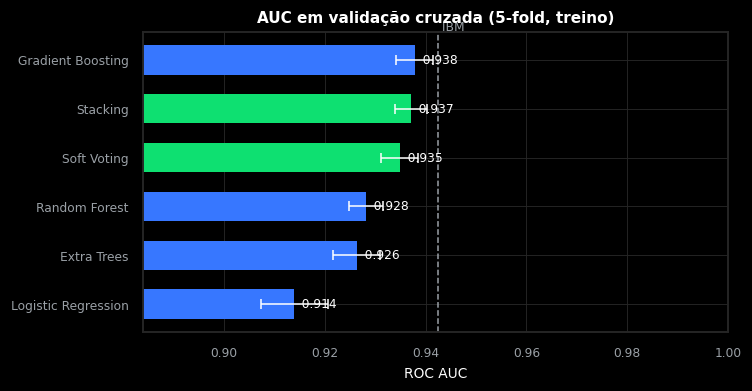

Modelo selecionado (maior AUC em CV): Gradient Boosting
Referência - AUC do Churn Score IBM no treino: 0.942


In [7]:
# Criar os 4 modelos afinados + os 2 ensembles
models = modelling.build_models(NUM, CAT, best_params)

# Comparar todos na mesma validação cruzada
cv_table = modelling.cv_compare(models, X_train, y_train)
cv_table.to_csv(TAB_DIR / "11_cv_modelos.csv")
display(style_table(cv_table, precision=4, highlight="auc"))

# AUC do Churn Score da IBM no treino (a fasquia a bater)
auc_ibm_train = modelling.score_metrics(y_train, train["Churn Score"] / 100)["auc"]
plots.plot_cv_comparison(cv_table, benchmark_auc=auc_ibm_train, show=SHOW)

# Escolher o modelo com maior AUC
BEST = cv_table["auc"].idxmax()
print("Modelo selecionado (maior AUC em CV):", BEST)
print("Referência - AUC do Churn Score IBM no treino:", round(auc_ibm_train, 3))

<div style='background:#000000;border-left:6px solid #3777FF;border-radius:8px;padding:14px 20px;margin:4px 0;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif'><h2 style='color:#3777FF;margin:0 0 8px 0'>5 · Satisfaction Score — com e sem</h2><div style='color:#FFFFFF;font-size:14px;line-height:1.6'>
<p>No notebook 01, <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>Satisfaction Score</code> 1–2 corresponde a 100% de churn: suspeita de ser registada no contexto da saída.
Treinamos o modelo selecionado <b style='color:#0EE071'>com e sem</b> a variável, no mesmo 5-fold, e documentamos a diferença.</p>
<p>Se o ganho for grande, é sinal de leakage: a versão com a variável <b style='color:#3777FF'>não serve para retenção preventiva</b>, porque o score só existe tarde demais.</p></div></div>

In [8]:
# Modelo A: SEM Satisfaction Score (é o modelo escolhido na secção 4)
modelo_sem = models[BEST]
cv_sem = modelling.cv_compare({BEST + " — sem Satisfaction": modelo_sem}, X_train, y_train)

# Modelo B: COM Satisfaction Score (igual, mas com mais uma coluna numérica)
NUM_SAT = NUM + ["Satisfaction Score"]
FEATURES_SAT = NUM_SAT + CAT
modelo_com = modelling.build_models(NUM_SAT, CAT, best_params)[BEST]
cv_com = modelling.cv_compare({BEST + " — com Satisfaction": modelo_com}, train[FEATURES_SAT], y_train)

# Juntar as duas linhas numa só tabela
sat_cv = pd.concat([cv_sem, cv_com])
display(style_table(sat_cv, precision=4, highlight="auc"))

auc_sem = cv_sem["auc"].iloc[0]   # iloc[0] = primeira (e única) linha
auc_com = cv_com["auc"].iloc[0]
print("Diferença de AUC (com - sem):", round(auc_com - auc_sem, 4))

,auc,auc_std,pr_auc,brier
modelo,,,,
Gradient Boosting — sem Satisfaction,0.9378,0.0036,0.8827,0.0855
Gradient Boosting — com Satisfaction,0.9947,0.0010,0.9894,0.0215


Diferença de AUC (com - sem): 0.0569


<div style='background:#000000;border-left:6px solid #3777FF;border-radius:8px;padding:14px 20px;margin:4px 0;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif'><h2 style='color:#3777FF;margin:0 0 8px 0'>6 · City com TargetEncoder</h2><div style='color:#FFFFFF;font-size:14px;line-height:1.6'>
<p><code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>City</code> tem ~1.100 valores distintos: one-hot é inviável. O <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>TargetEncoder</code> substitui cada cidade pela taxa de churn suavizada,
calculada com <i>cross-fitting</i> e <b style='color:#0EE071'>dentro do Pipeline</b> — em cada fold só vê o treino desse fold.</p>
<p>Só entra no modelo final se melhorar o AUC em CV de forma clara (mais do que o desvio-padrão entre folds).</p></div></div>

In [9]:
# Mesmo modelo, mas com a coluna City (codificada com TargetEncoder)
FEATURES_CITY = FEATURES + ["City"]
city_model = modelling.build_models(NUM, CAT, best_params, te=["City"])[BEST]
city_cv = modelling.cv_compare({BEST + " + City (TargetEncoder)": city_model}, train[FEATURES_CITY], y_train)

variants = pd.concat([sat_cv, city_cv])
variants.to_csv(TAB_DIR / "12_variantes_satisfaction_city.csv")
display(style_table(variants, precision=4, highlight="auc"))

# Só usamos City se o ganho for maior do que o desvio-padrão entre folds
auc_com_city = city_cv["auc"].iloc[0]
auc_sem_city = cv_table.loc[BEST, "auc"]
desvio = cv_table.loc[BEST, "auc_std"]

gain = auc_com_city - auc_sem_city
USE_CITY = gain > desvio

print("Ganho de AUC com City:", round(gain, 4))
print("Incluir City no modelo final?", USE_CITY)

,auc,auc_std,pr_auc,brier
modelo,,,,
Gradient Boosting — sem Satisfaction,0.9378,0.0036,0.8827,0.0855
Gradient Boosting — com Satisfaction,0.9947,0.0010,0.9894,0.0215
Gradient Boosting + City (TargetEncoder),0.9385,0.0035,0.8839,0.0852


Ganho de AUC com City: 0.0007
Incluir City no modelo final? False


<div style='background:#000000;border-left:6px solid #3777FF;border-radius:8px;padding:14px 20px;margin:4px 0;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif'><h2 style='color:#3777FF;margin:0 0 8px 0'>7 · Avaliação final no holdout</h2><div style='color:#FFFFFF;font-size:14px;line-height:1.6'>
<p>O holdout (20%) é usado <b style='color:#0EE071'>uma única vez</b>: todos os modelos são treinados no treino completo e avaliados no teste.
O modelo final já foi escolhido na secção 4; os restantes aparecem só para transparência.</p>
<p>O <b style='color:#3777FF'>Churn Score IBM</b> é avaliado no mesmo holdout — é a fasquia a bater. O seu Brier é dado apenas como referência: <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>Churn Score / 100</code> não é uma probabilidade calibrada. A versão com Satisfaction Score é reportada à parte, para documentar o efeito do leakage.</p></div></div>

,auc,pr_auc,brier
Gradient Boosting + Satisfaction (leakage),0.9959,0.9912,0.0203
Churn Score IBM (benchmark),0.9408,0.8762,0.2142
Stacking,0.9375,0.8842,0.0889
Soft Voting,0.9363,0.8822,0.0879
Gradient Boosting,0.9362,0.8826,0.0865
Random Forest,0.9287,0.8736,0.0901
Extra Trees,0.9256,0.8696,0.0928
Logistic Regression,0.9185,0.8192,0.1022


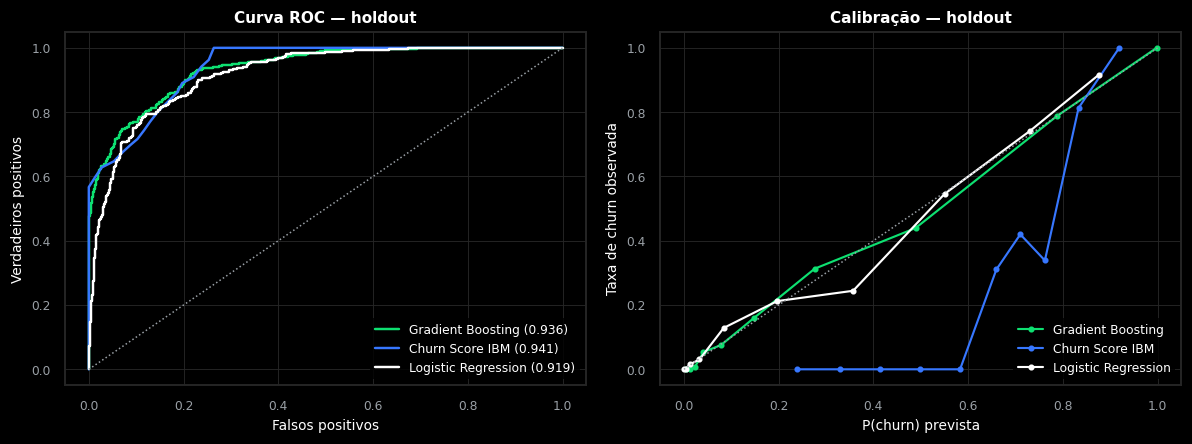

In [10]:
# Definir o modelo final e as suas colunas
if USE_CITY:
    final_model = city_model
    FINAL_FEATURES = FEATURES_CITY
else:
    final_model = models[BEST]
    FINAL_FEATURES = FEATURES

# Treinar cada modelo no treino completo e prever P(churn) no teste
# predict_proba devolve 2 colunas: [P(fica), P(sai)] -> ficamos com a coluna 1
probas = {}
for name in models:
    model = models[name]
    model.fit(X_train, y_train)
    probas[name] = model.predict_proba(X_test)[:, 1]

# Se o modelo final usa City, treiná-lo com essas colunas e substituir a previsão
if USE_CITY:
    final_model.fit(train[FINAL_FEATURES], y_train)
    probas[BEST] = final_model.predict_proba(test[FINAL_FEATURES])[:, 1]

# Versão com Satisfaction Score (só para mostrar o efeito do leakage)
modelo_com.fit(train[FEATURES_SAT], y_train)
probas[BEST + " + Satisfaction (leakage)"] = modelo_com.predict_proba(test[FEATURES_SAT])[:, 1]

# Tabela de métricas no teste (inclui o Churn Score IBM)
holdout = modelling.holdout_report(probas, y_test, test["Churn Score"])
holdout.to_csv(TAB_DIR / "13_holdout.csv")
display(style_table(holdout, precision=4, highlight="auc"))

# Curva ROC e calibração
p_test = probas[BEST]   # P(churn) do modelo final para cada cliente do teste
curvas = {
    BEST: p_test,
    "Churn Score IBM": test["Churn Score"] / 100,
    "Logistic Regression": probas["Logistic Regression"],
}
plots.plot_roc_calibration(y_test, curvas, show=SHOW)

<div style='background:#000000;border-left:6px solid #3777FF;border-radius:8px;padding:14px 20px;margin:4px 0;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif'><h2 style='color:#3777FF;margin:0 0 8px 0'>8 · Interpretação</h2><div style='color:#FFFFFF;font-size:14px;line-height:1.6'>
<p><b style='color:#0EE071'>Permutation importance</b> no holdout: quanto cai o AUC quando os valores de uma variável são baralhados.
Funciona para qualquer modelo (incluindo ensembles) e ao nível das variáveis originais, não das colunas one-hot — mais útil para explicar ao Head of Customer Retention.</p>
<p>Barras <b style='color:#3777FF'>azuis</b> = numéricas, <b style='color:#0EE071'>verdes</b> = categóricas.</p></div></div>

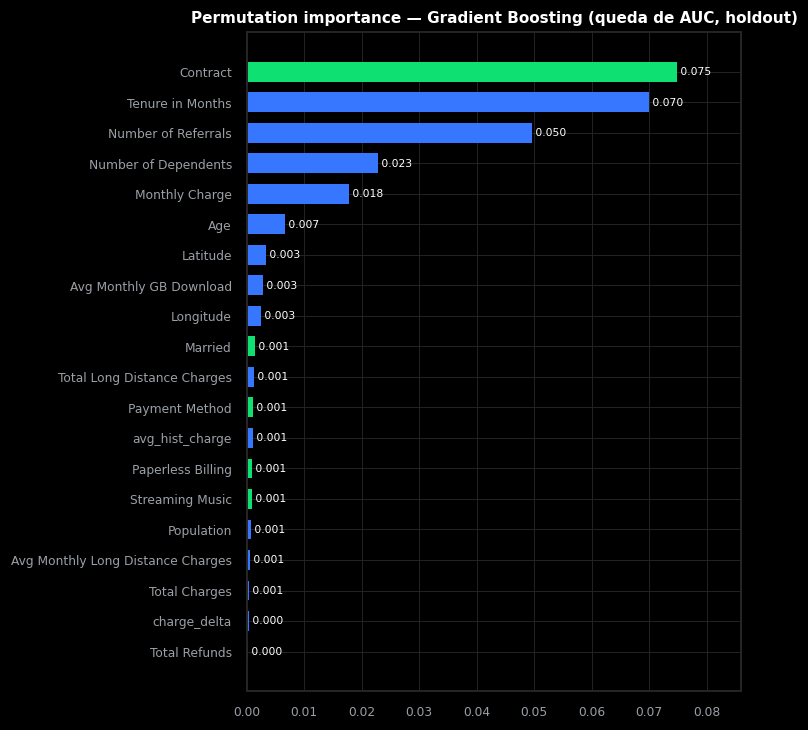

In [11]:
# Quanto cai o AUC quando baralhamos os valores de cada coluna?
pi = permutation_importance(final_model, test[FINAL_FEATURES], y_test, scoring="roc_auc",
                            n_repeats=5, random_state=0, n_jobs=-1)

importance = pd.Series(pi.importances_mean, index=FINAL_FEATURES)
importance = importance.clip(lower=0)                  # valores negativos passam a 0
importance = importance.sort_values(ascending=False)   # da mais para a menos importante
importance.to_frame("queda_auc").to_csv(TAB_DIR / "14_importancia_permutacao.csv")

titulo = "Permutation importance — " + BEST + " (queda de AUC, holdout)"
plots.plot_ranking(importance.head(20), titulo, "27_importancia_permutacao",
                   highlight=set(CAT + ["City"]), show=SHOW)

<div style='background:#000000;border-left:6px solid #3777FF;border-radius:8px;padding:14px 20px;margin:4px 0;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif'><h2 style='color:#3777FF;margin:0 0 8px 0'>9 · Priorização: P(churn) × CLTV</h2><div style='color:#FFFFFF;font-size:14px;line-height:1.6'>
<p>O objetivo não é só prever churn, é decidir <b style='color:#3777FF'>quem contactar primeiro</b>. Cada cliente recebe uma
<b style='color:#0EE071'>perda esperada = P(churn) × CLTV</b> e a lista de intervenção é ordenada por esse valor.</p>
<p>A <b style='color:#0EE071'>curva de captura</b> mede, no holdout, que % do CLTV dos clientes que de facto saíram fica coberta ao contactar os top-k% da lista.
Compara quatro ordenações: o nosso P × CLTV, só P(churn), o Churn Score IBM × CLTV e o Churn Score IBM sozinho.</p></div></div>

,top 10%,top 20%,top 30%
Gradient Boosting: P × CLTV,0.393,0.624,0.779
Gradient Boosting: só P(churn),0.349,0.625,0.770
IBM: Churn Score × CLTV,0.328,0.543,0.681
IBM: só Churn Score,0.348,0.617,0.746


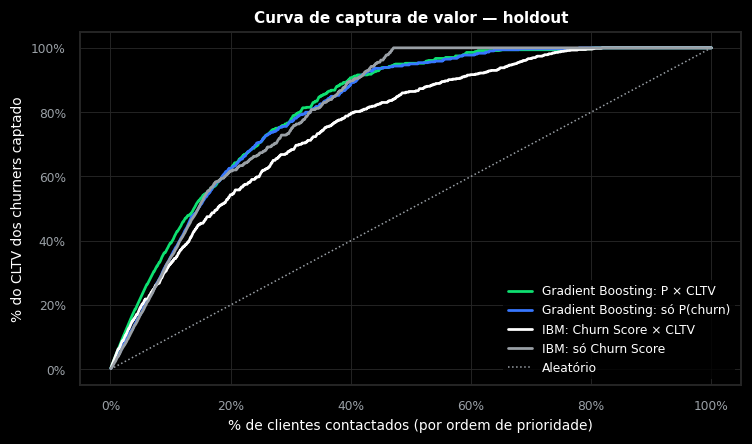

In [12]:
# 4 formas diferentes de ordenar os clientes do teste
orderings = {
    BEST + ": P × CLTV": p_test * test["CLTV"],
    BEST + ": só P(churn)": p_test,
    "IBM: Churn Score × CLTV": test["Churn Score"] * test["CLTV"],
    "IBM: só Churn Score": test["Churn Score"],
}

# Que % do CLTV perdido apanhamos ao contactar os primeiros k% de cada lista?
curve = modelling.capture_curve(y_test, test["CLTV"], orderings)
capture = modelling.capture_at(curve, cuts=(0.1, 0.2, 0.3))
capture.to_csv(TAB_DIR / "15_captura_valor.csv")
display(style_table(capture, precision=3))
plots.plot_capture_curve(curve, show=SHOW)

<div style='background:#000000;border-left:6px solid #0EE071;border-radius:8px;padding:14px 20px;margin:4px 0;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif'><h3 style='color:#0EE071;margin:0 0 6px 0'>9.1 · Lista de intervenção</h3><div style='color:#FFFFFF;font-size:13.5px;line-height:1.6'>
<p>Lista ordenada para o holdout (onde podemos verificar o resultado) e para os clientes <b style='color:#3777FF'>Joined</b>, que ficaram fora do treino.
O mapa mostra onde ficam os top-N: o P × CLTV troca alguns clientes de risco alto mas pouco valor por clientes de valor alto com risco moderado.</p>
<p><code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>TOP_N</code> é o orçamento de contactos — ajustar ao que a equipa de retenção consegue tratar.</p>
<p><b style='color:#0EE071'>Atenção aos Joined:</b> são clientes com poucos meses de casa. Na população de treino, tenure baixa está fortemente associada a churn,
por isso o modelo tende a dar-lhes P(churn) muito alta — é <b style='color:#3777FF'>extrapolação</b>, não um resultado validado.
A lista dos Joined deve ser lida como ordenação relativa e não como probabilidade calibrada.</p></div></div>

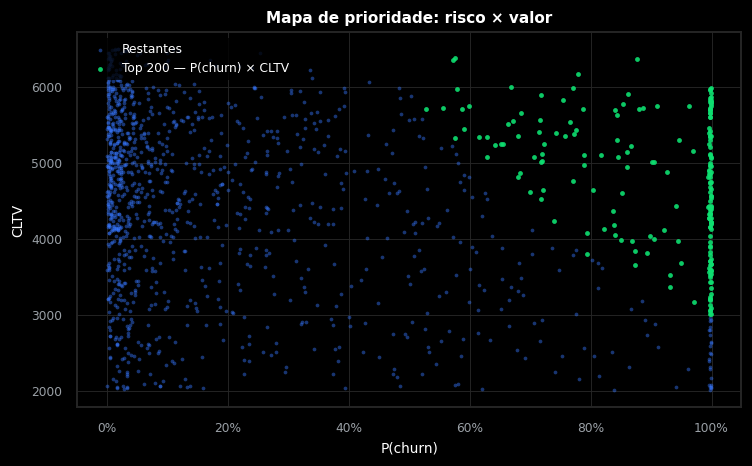

,clientes,p_churn_media,churn_real,cltv_medio,perda_esperada
decil,,,,,
1,132,0.936,0.939,5045.962,620113.997
2,132,0.777,0.727,4144.598,402525.784
3,132,0.523,0.508,4123.545,253764.653
4,131,0.301,0.382,4173.565,149782.068
5,132,0.156,0.144,4458.288,84837.987
6,132,0.079,0.083,4541.614,44256.383
7,131,0.043,0.031,4642.771,24212.833
8,132,0.024,0.008,4614.288,13660.348
9,132,0.013,0.015,4368.553,6932.273


,Customer ID,CLTV,p_churn,perda_esperada,rank,decil,churn
0,9399-APLBT,5980,0.999,5971.618,1,1,1
1,0295-PPHDO,5962,0.997,5943.771,2,1,1
2,3027-ZTDHO,5951,0.998,5938.634,3,1,1
3,6996-KNSML,5919,0.998,5909.121,4,1,1
4,3746-EUBYR,5861,0.999,5856.189,5,1,1
5,8062-YBDOE,5844,0.997,5825.237,6,1,1
6,1612-EOHDH,5828,0.998,5819.230,7,1,1
7,9514-JDSKI,5828,0.998,5817.162,8,1,1
8,3716-BDVDB,5795,0.999,5791.144,9,1,1
9,3178-FESZO,5797,0.998,5787.322,10,1,1


In [13]:
TOP_N = 200   # nº de clientes que a equipa de retenção consegue contactar

# Lista de prioridade do teste + coluna com o churn real (para verificar)
prio_test = modelling.priority_list(test, p_test)
churn_real = test[["Customer ID", TARGET]]
prio_test = prio_test.merge(churn_real, on="Customer ID")
plots.plot_priority_map(prio_test, TOP_N, show=SHOW)

# Resumo por decil (decil 1 = 10% de clientes com maior perda esperada)
grupos = prio_test.groupby("decil")
by_decile = pd.DataFrame({
    "clientes": grupos.size(),
    "p_churn_media": grupos["p_churn"].mean(),
    "churn_real": grupos[TARGET].mean(),
    "cltv_medio": grupos["CLTV"].mean(),
    "perda_esperada": grupos["perda_esperada"].sum(),
})
display(style_table(by_decile, precision=3, highlight="churn_real"))
display(style_table(prio_test.head(15), precision=3))

In [14]:
# Clientes Joined: novos clientes, sem resposta conhecida -> só prever (é extrapolação, ver nota acima)
p_joined = final_model.predict_proba(joined[FINAL_FEATURES])[:, 1]
prio_joined = modelling.priority_list(joined, p_joined)

print("Joined:", len(prio_joined), "clientes | P(churn) média:", round(p_joined.mean() * 100, 1), "%")
display(style_table(prio_joined.head(15), precision=3))

Joined: 454 clientes | P(churn) média: 96.0 %


,Customer ID,CLTV,p_churn,perda_esperada,rank,decil
0,9818-XQCUV,5994,0.997,5975.062,1,1
1,8713-IGZSO,5983,0.996,5957.002,2,1
2,0455-XFASS,5998,0.993,5955.670,3,1
3,3420-YJLQT,5965,0.998,5951.001,4,1
4,2792-LSHWX,5960,0.997,5944.535,5,1
5,6629-LADHQ,5968,0.995,5940.577,6,1
6,0178-CIIKR,5949,0.995,5919.548,7,1
7,3961-SXAXY,5925,0.998,5914.712,8,1
8,1453-RZFON,5969,0.990,5906.485,9,1
9,6650-VJONK,5913,0.998,5903.149,10,1


<div style='background:#000000;border-left:6px solid #3777FF;border-radius:8px;padding:14px 20px;margin:4px 0;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif'><h2 style='color:#3777FF;margin:0 0 8px 0'>10 · Exportação</h2><div style='color:#FFFFFF;font-size:14px;line-height:1.6'>
<p>Ficheiros gerados (ignorados pelo Git):</p>
<ul style='margin:6px 0 2px 0'><li><code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>outputs/artifacts/final_model.joblib</code> — modelo final treinado, lista de features e métricas</li><li><code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>data/processed/prioridade_holdout.csv</code> e <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>prioridade_joined.csv</code> — listas de intervenção ordenadas</li><li><code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>outputs/tables/10_*</code> a <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>15_*</code> e <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>outputs/figures/2*_</code> — tabelas e gráficos desta fase</li></ul></div></div>

In [15]:
# Guardar o modelo final e a informação necessária para o voltar a usar
bundle = {
    "model": final_model,
    "name": BEST,
    "features": FINAL_FEATURES,
    "target": TARGET,
    "best_params": best_params,
    "holdout": holdout.loc[BEST].to_dict(),
}
joblib.dump(bundle, ARTIFACTS_DIR / "final_model.joblib")

# Guardar as listas de prioridade
prio_test.to_csv(DATA_PROCESSED / "prioridade_holdout.csv", index=False)
prio_joined.to_csv(DATA_PROCESSED / "prioridade_joined.csv", index=False)

print("Guardado: outputs/artifacts/final_model.joblib")
print("Guardado: data/processed/prioridade_holdout.csv")
print("Guardado: data/processed/prioridade_joined.csv")

Guardado: outputs/artifacts/final_model.joblib
Guardado: data/processed/prioridade_holdout.csv
Guardado: data/processed/prioridade_joined.csv


<div style='background:#000000;border-left:6px solid #3777FF;border-radius:8px;padding:14px 20px;margin:4px 0;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif'><h2 style='color:#3777FF;margin:0 0 8px 0'>11 · Conclusões para o relatório</h2><div style='color:#FFFFFF;font-size:14px;line-height:1.6'>
<p>A célula seguinte resume os números-chave a partir das tabelas acima, para transcrever para o relatório:</p>
<ul style='margin:6px 0 2px 0'><li>desempenho do modelo final vs <b style='color:#3777FF'>Churn Score IBM</b> no mesmo holdout</li><li>efeito do <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>Satisfaction Score</code> (leakage) e decisão sobre <code style='color:#0EE071;background:#111111;padding:1px 5px;border-radius:3px'>City</code></li><li>ganho de valor captado com a priorização <b style='color:#0EE071'>P(churn) × CLTV</b></li></ul></div></div>

In [16]:
# Números-chave para o relatório
auc_modelo = holdout.loc[BEST, "auc"]
auc_ibm = holdout.loc["Churn Score IBM (benchmark)", "auc"]
pr_auc = holdout.loc[BEST, "pr_auc"]
brier = holdout.loc[BEST, "brier"]
auc_sat = holdout.loc[BEST + " + Satisfaction (leakage)", "auc"]

captura_modelo = capture.loc[BEST + ": P × CLTV", "top 20%"]
captura_ibm = capture.loc["IBM: só Churn Score", "top 20%"]

print("Modelo final:", BEST)
print("  AUC no teste:", round(auc_modelo, 3))
print("  AUC do IBM:  ", round(auc_ibm, 3))
print("  Diferença:   ", round(auc_modelo - auc_ibm, 3))
print("  PR-AUC:", round(pr_auc, 3), "| Brier:", round(brier, 3))
print("Satisfaction Score: AUC com a variável =", round(auc_sat, 3), "(fora do modelo final)")
print("City incluída no modelo final?", USE_CITY, "(ganho CV:", round(gain, 4), ")")
print("Contactando 20% dos clientes:")
print("  P × CLTV capta", round(captura_modelo * 100, 1), "% do CLTV perdido")
print("  Churn Score IBM capta", round(captura_ibm * 100, 1), "%")

Modelo final: Gradient Boosting
  AUC no teste: 0.936
  AUC do IBM:   0.941
  Diferença:    -0.005
  PR-AUC: 0.883 | Brier: 0.086
Satisfaction Score: AUC com a variável = 0.996 (fora do modelo final)
City incluída no modelo final? False (ganho CV: 0.0007 )
Contactando 20% dos clientes:
  P × CLTV capta 62.4 % do CLTV perdido
  Churn Score IBM capta 61.7 %
